# Exercise 5 - Solution
***

> **Aim:** To find the best fitting Euler pole of rotation between South America and Africa, based on the geometry of the fracture zones.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as optm

#let's start by reading in the ridges so we have these available later for plotting
# we are not going to use the ridges in the inversion to find the plate pole
# (the data are in the exercises folder)
dr = pd.read_csv('../exercises/data/gale_ridge_segs.csv', header=0, index_col=None)
#we should now restrict the ridges to those in the geographical region we are interested in
# reset_index(drop=True) renumbers the rows from 0, and drop=True stops pandas keeping the
# old row numbers as an extra column
lonmin, lonmax, latmin, latmax = -60., -5., -6., 20.
dr = dr[(dr.Lat1<latmax) & (dr.Lat1>latmin) & (dr.Lat2<latmax) & (dr.Lat2>latmin) &
        (dr.Lon1<lonmax) & (dr.Lon1>lonmin) & (dr.Lon2<lonmax) & (dr.Lon2>lonmin)].reset_index(drop=True)

#now we can read in the fracture zones
df = pd.read_csv('../exercises/data/fracture_zones.csv', header=0, index_col=0)

#we need our oblique Mercator projection code
# point is an array with a row for each point, and columns of latitude and longitude
def obq_mc(point, pole, center):
    """Project points into the x, y coordinates of an oblique Mercator projection.

    point has a row for each point, with columns of latitude and longitude (degrees),
    pole is the [latitude, longitude] of the projection pole, and center is the central longitude.
    """
    #critically, we need to remember a degrees to radians conversion
    lat = np.deg2rad(point[:,0])
    lon = np.deg2rad(point[:,1])
    plat = np.deg2rad(pole[0])
    cnt = np.deg2rad(center)

    #numpy works on whole arrays at once, so we don't need to loop over the points
    A = np.sin(plat)*np.sin(lat) - np.cos(plat)*np.cos(lat)*np.sin(lon-cnt)

    #np.arctan2 takes the numerator and the denominator separately, so it can tell which
    # quadrant the angle is in
    x = np.arctan2(np.tan(lat)*np.cos(plat) + np.sin(plat)*np.sin(lon-cnt), np.cos(lon-cnt))
    y = 0.5 * np.log((1+A)/(1-A))

    return x, y

#now we set up our misfit function
# it is expecting a dataframe with .lat1, .lat2, .lon1, and .lon2
# a minimum (i.e., best fit pole) is when each pair of y values is identical
def misfit(pole, df):
    """Return the root mean squared misfit of the fracture zones from horizontal lines.

    The y values of the two ends of each fracture zone are compared after projecting about pole.
    """
    #this needs to be defined for the oblique projection: a centre 90deg
    # away from the pole
    center = pole[1]+90

    #now, perform the transformation on the start and ends of each transform fault
    x1, y1 = obq_mc(np.vstack([df.lat1, df.lon1]).transpose(), pole, center)
    x2, y2 = obq_mc(np.vstack([df.lat2, df.lon2]).transpose(), pole, center)

    #return the root mean squared misfit between the two ends of each fracture zone
    return np.sqrt(np.sum((y1 - y2)**2) / len(y1))

#we will plot the projected ridges and fracture zones more than once, so let's write a function for it
def plot_projected(pole, title):
    """Plot the ridges and fracture zones projected about pole, and return the figure."""
    #calculate the projected coordinates, first for the fracture zones, then for the ridges
    x1f, y1f = obq_mc(np.vstack([df.lat1, df.lon1]).transpose(), pole, pole[1]+90)
    x2f, y2f = obq_mc(np.vstack([df.lat2, df.lon2]).transpose(), pole, pole[1]+90)
    x1r, y1r = obq_mc(np.vstack([dr.Lat1, dr.Lon1]).transpose(), pole, pole[1]+90)
    x2r, y2r = obq_mc(np.vstack([dr.Lat2, dr.Lon2]).transpose(), pole, pole[1]+90)

    fig, ax = plt.subplots(1, figsize=(10,6))
    #now we want to pair each x1,y1 with x2,y2 to plot the segments
    # first for the ridges
    for i in range(len(x1r)):
        ax.plot([x1r[i], x2r[i]], [y1r[i], y2r[i]], linestyle='-', color='black')
    # now for the fracture zones
    for i in range(len(x1f)):
        ax.plot([x1f[i], x2f[i]], [y1f[i], y2f[i]], linestyle='-', color='orangered')

    #it isn't often you get to label x and y axes with x and y, so take the opportunity!
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_title(title);
    return fig

First, let's test our oblique Mercator function, using a pole at 90N (and longitude 0, which puts the centre of the projection at 90E, so our region isn't split across the edge of the map). This should look like the ordinary Mercator map in the exercise.

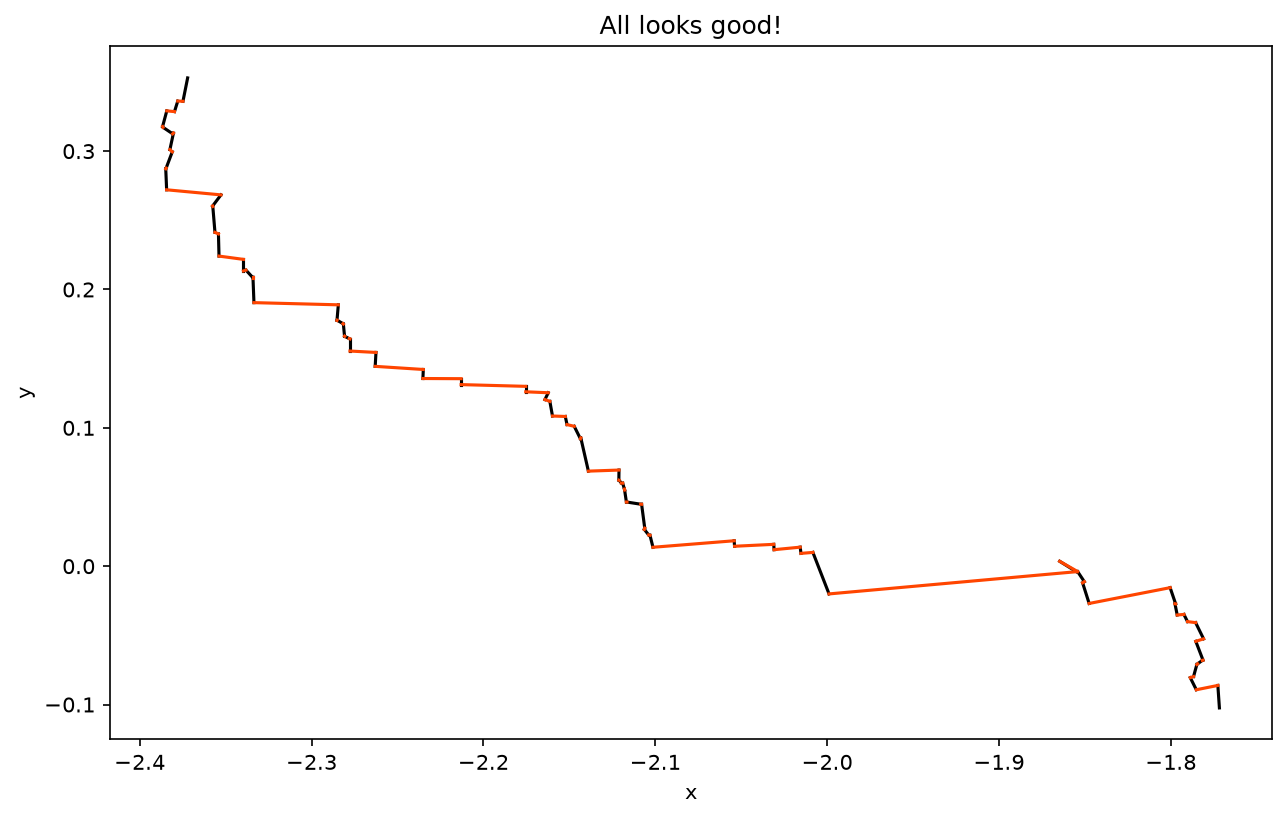

In [2]:
plot_projected([90, 0], 'All looks good!');

Now let's find the best fitting pole with the dual annealing solver.

 message: ['Maximum number of iteration reached']
 success: True
  status: 0
     fun: 0.0017199060122170542
       x: [ 6.676e+01 -3.610e+01]
     nit: 1000
    nfev: 4061
    njev: 20
    nhev: 0
DeMets 1994 pole [ 62.5 -39.4] with a fracture zone misfit of 0.0022046800825710733
Our best fit pole ['66.76', '-36.10'] with a fracture zone misfit of 0.0017199060122170542


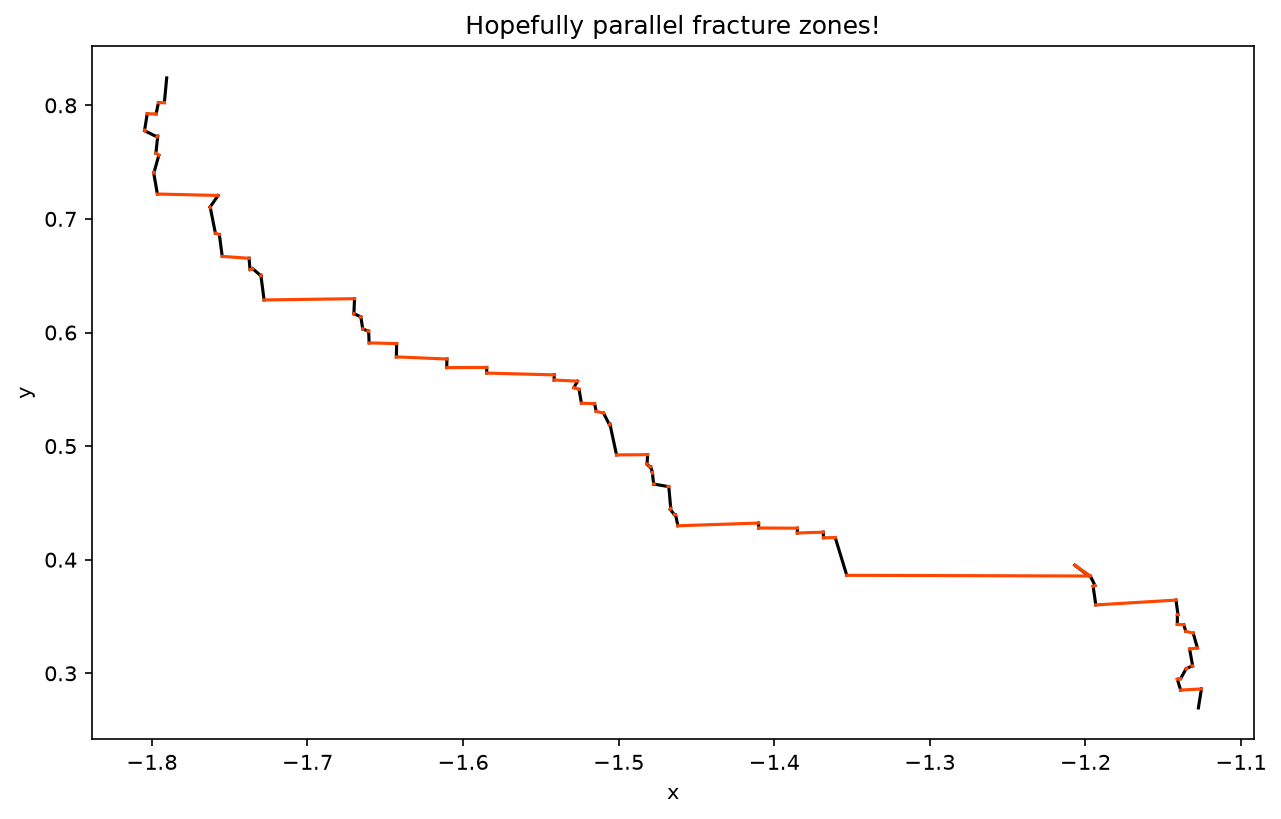

In [3]:
#the pole's latitude can be from 0 to 90 (we only need the 'north' end of the pole),
# and its longitude from -180 to 180
bounds = list(zip([0, -180], [90, 180]))

#args must be a tuple, so we write (df,) to make a tuple containing just df.
# Setting 'seed' makes the solver's random choices the same each time we run it, so we get the same answer.
res = optm.dual_annealing(misfit, bounds=bounds, args=(df,), seed=42)
print(res)

pole = np.array([62.5, -39.4])
print('DeMets 1994 pole', pole, 'with a fracture zone misfit of', misfit(pole, df))

pole = res.x
print('Our best fit pole', [f'{p:.2f}' for p in pole], 'with a fracture zone misfit of', misfit(pole, df))

fig = plot_projected(pole, 'Hopefully parallel fracture zones!')

#save the figure to a file
fig.savefig('exercise5_best_fit.png', dpi=300, bbox_inches='tight')